In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
with open("fd_data_s11_emp.pickle", "rb") as f:
    s11_data = pickle.load(f)

print("S11 data loaded successfully!")
print("Shape:", s11_data.shape)
print("Data type:", s11_data.dtype)

S11 data loaded successfully!
Shape: (200, 1001, 72)
Data type: complex128


/tmp/ipykernel_5931/724165786.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  s11_data = pickle.load(f)


In [4]:
with open("md_list_s11_emp.pickle", "rb") as f:
    metadata = pickle.load(f)

print("Metadata loaded successfully!")
print("Number of experiments:", len(metadata))

Metadata loaded successfully!
Number of experiments: 200


In [5]:
print("Complete dataset shape:", s11_data.shape)
print("One experiment shape:", s11_data[0].shape)
print("Data type:", s11_data.dtype)

print("\nFirst S11 value:")
print(s11_data[0, 0, 0])

Complete dataset shape: (200, 1001, 72)
One experiment shape: (1001, 72)
Data type: complex128

First S11 value:
(0.0007030974578160487+0.0028864345427280225j)


In [6]:
metadata_df = pd.DataFrame(metadata)

print("Metadata shape:", metadata_df.shape)

metadata_df.head()

Metadata shape: (200, 22)


,n_expt,id,phant_id,tum_diam,tum_shape,tum_x,tum_y,tum_z,birads,adi_ref_id,...,n_session,ant_rad,ant_z,fib_ang,adi_x,adi_y,fib_ref_id,fib_x,fib_y,tum_in_fib
0,1,1,A2F1,3.0,sphere,2.25,2.25,-6.5,1,3,...,1,18.0,-6.5,0.0,0.0,0.0,2.0,0.0,0.0,0.0
1,2,2,A2F1,NaN,,NaN,NaN,NaN,1,3,...,1,18.0,-6.5,0.0,0.0,0.0,NaN,0.0,0.0,NaN
2,4,4,A2F1,2.5,sphere,2.25,2.25,-6.5,1,6,...,1,18.0,-6.5,0.0,0.0,0.0,5.0,0.0,0.0,0.0
3,5,5,A2F1,NaN,,NaN,NaN,NaN,1,6,...,1,18.0,-6.5,0.0,0.0,0.0,NaN,0.0,0.0,NaN
4,7,7,A2F1,2.0,sphere,2.25,2.25,-6.5,1,9,...,1,18.0,-6.5,0.0,0.0,0.0,8.0,0.0,0.0,0.0


In [7]:
print("Tumor diameters:")
print(metadata_df["tum_diam"].value_counts(dropna=False))

Tumor diameters:
tum_diam
NaN    100
3.0     20
2.5     20
2.0     20
1.5     20
1.0     20
Name: count, dtype: int64


In [8]:
print("Tumor X coordinates:")
print(metadata_df["tum_x"].value_counts(dropna=False))

print("\nTumor Y coordinates:")
print(metadata_df["tum_y"].value_counts(dropna=False))

print("\nTumor Z coordinates:")
print(metadata_df["tum_z"].value_counts(dropna=False))

Tumor X coordinates:
tum_x
 NaN     100
-2.25     85
 2.25     15
Name: count, dtype: int64

Tumor Y coordinates:
tum_y
 NaN     100
-2.25     80
 2.25     20
Name: count, dtype: int64

Tumor Z coordinates:
tum_z
-6.5    100
 NaN    100
Name: count, dtype: int64


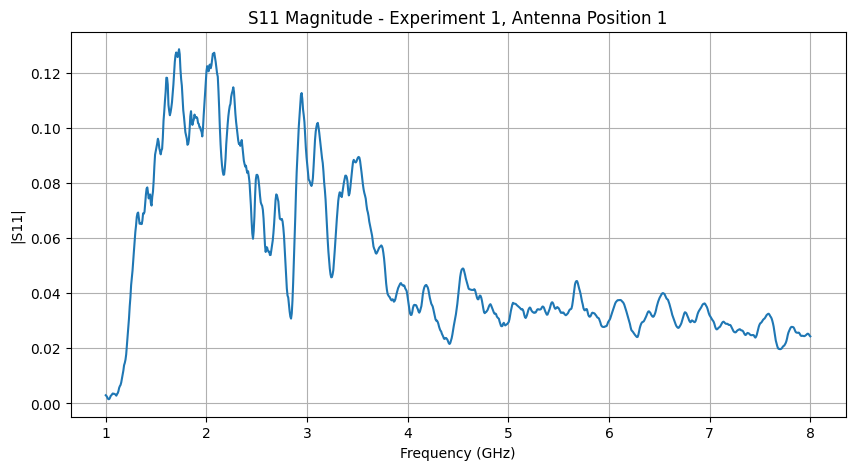

In [9]:
# Select experiment 0 and antenna position 0
s11_signal = s11_data[0, :, 0]

# Calculate magnitude
magnitude = np.abs(s11_signal)

# Frequency axis
frequency = np.linspace(1, 8, 1001)  # GHz

plt.figure(figsize=(10, 5))

plt.plot(frequency, magnitude)

plt.xlabel("Frequency (GHz)")
plt.ylabel("|S11|")
plt.title("S11 Magnitude - Experiment 1, Antenna Position 1")
plt.grid(True)

plt.show()

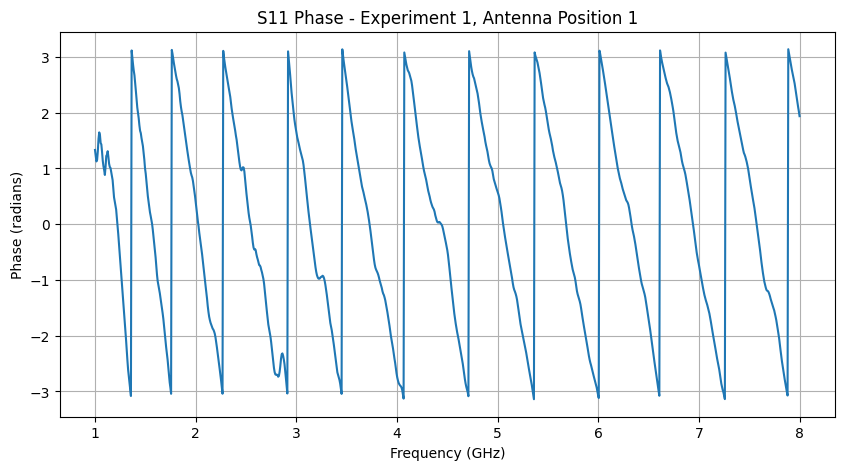

In [10]:
phase = np.angle(s11_signal)

plt.figure(figsize=(10, 5))

plt.plot(frequency, phase)

plt.xlabel("Frequency (GHz)")
plt.ylabel("Phase (radians)")
plt.title("S11 Phase - Experiment 1, Antenna Position 1")
plt.grid(True)

plt.show()

In [11]:
# Identify tumor and reference/no-tumor experiments

tumor_mask = metadata_df["tum_diam"].notna()
reference_mask = metadata_df["tum_diam"].isna()

print("Total experiments:", len(metadata_df))
print("Tumor experiments:", tumor_mask.sum())
print("Reference experiments:", reference_mask.sum())

Total experiments: 200
Tumor experiments: 100
Reference experiments: 100


In [12]:
tumor_df = metadata_df[tumor_mask].copy()

print("Number of tumor experiments:", len(tumor_df))

tumor_df[
    ["id", "phant_id", "tum_diam", "tum_shape", "tum_x", "tum_y", "tum_z"]
].head(20)

Number of tumor experiments: 100


,id,phant_id,tum_diam,tum_shape,tum_x,tum_y,tum_z
0,1,A2F1,3.0,sphere,2.25,2.25,-6.5
2,4,A2F1,2.5,sphere,2.25,2.25,-6.5
4,7,A2F1,2.0,sphere,2.25,2.25,-6.5
6,10,A2F1,1.5,sphere,2.25,2.25,-6.5
8,13,A2F1,1.0,sphere,2.25,2.25,-6.5
10,17,A2F11,3.0,sphere,-2.25,2.25,-6.5
12,20,A2F11,2.5,sphere,-2.25,2.25,-6.5
14,23,A2F11,2.0,sphere,-2.25,2.25,-6.5
16,26,A2F11,1.5,sphere,-2.25,2.25,-6.5
18,29,A2F11,1.0,sphere,-2.25,2.25,-6.5


In [13]:
print("Unique X coordinates:")
print(sorted(tumor_df["tum_x"].dropna().unique()))

print("\nUnique Y coordinates:")
print(sorted(tumor_df["tum_y"].dropna().unique()))

print("\nUnique Z coordinates:")
print(sorted(tumor_df["tum_z"].dropna().unique()))

Unique X coordinates:
[np.float64(-2.25), np.float64(2.25)]

Unique Y coordinates:
[np.float64(-2.25), np.float64(2.25)]

Unique Z coordinates:
[np.float64(-6.5)]


In [14]:
print("First tumor experiment index:")
print(metadata_df.index[tumor_mask][0])

print("\nFirst reference experiment index:")
print(metadata_df.index[reference_mask][0])

First tumor experiment index:
0

First reference experiment index:
1


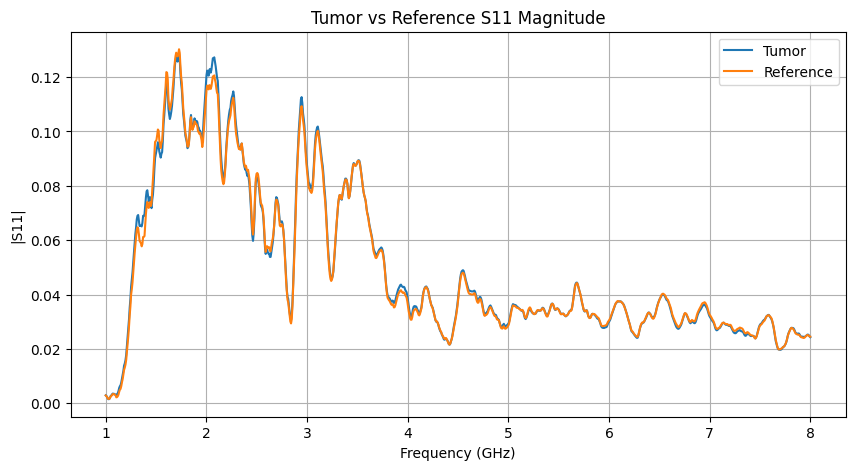

In [15]:
tumor_idx = metadata_df.index[tumor_mask][0]
reference_idx = metadata_df.index[reference_mask][0]

# Use antenna position 0
tumor_signal = s11_data[tumor_idx, :, 0]
reference_signal = s11_data[reference_idx, :, 0]

tumor_mag = np.abs(tumor_signal)
reference_mag = np.abs(reference_signal)

frequency = np.linspace(1, 8, 1001)

plt.figure(figsize=(10, 5))

plt.plot(frequency, tumor_mag, label="Tumor")
plt.plot(frequency, reference_mag, label="Reference")

plt.xlabel("Frequency (GHz)")
plt.ylabel("|S11|")
plt.title("Tumor vs Reference S11 Magnitude")
plt.legend()
plt.grid(True)

plt.show()

In [16]:
# Check tumor/reference pairing

for i in range(10):
    print(
        i,
        "ID:", metadata_df.loc[i, "id"],
        "Phantom:", metadata_df.loc[i, "phant_id"],
        "Tumor diameter:", metadata_df.loc[i, "tum_diam"]
    )

0 ID: 1 Phantom: A2F1 Tumor diameter: 3.0
1 ID: 2 Phantom: A2F1 Tumor diameter: nan
2 ID: 4 Phantom: A2F1 Tumor diameter: 2.5
3 ID: 5 Phantom: A2F1 Tumor diameter: nan
4 ID: 7 Phantom: A2F1 Tumor diameter: 2.0
5 ID: 8 Phantom: A2F1 Tumor diameter: nan
6 ID: 10 Phantom: A2F1 Tumor diameter: 1.5
7 ID: 11 Phantom: A2F1 Tumor diameter: nan
8 ID: 13 Phantom: A2F1 Tumor diameter: 1.0
9 ID: 14 Phantom: A2F1 Tumor diameter: nan


In [17]:
# Check whether tumor experiments are followed by
# reference measurements from the same phantom

for i in range(0, 20, 2):
    tumor = metadata_df.iloc[i]
    reference = metadata_df.iloc[i + 1]

    print(
        f"Pair {i//2 + 1}: "
        f"Tumor ID={tumor['id']}, "
        f"Reference ID={reference['id']}, "
        f"Same phantom={tumor['phant_id'] == reference['phant_id']}"
    )

Pair 1: Tumor ID=1, Reference ID=2, Same phantom=True
Pair 2: Tumor ID=4, Reference ID=5, Same phantom=True
Pair 3: Tumor ID=7, Reference ID=8, Same phantom=True
Pair 4: Tumor ID=10, Reference ID=11, Same phantom=True
Pair 5: Tumor ID=13, Reference ID=14, Same phantom=True
Pair 6: Tumor ID=17, Reference ID=18, Same phantom=True
Pair 7: Tumor ID=20, Reference ID=21, Same phantom=True
Pair 8: Tumor ID=23, Reference ID=24, Same phantom=True
Pair 9: Tumor ID=26, Reference ID=27, Same phantom=True
Pair 10: Tumor ID=29, Reference ID=30, Same phantom=True


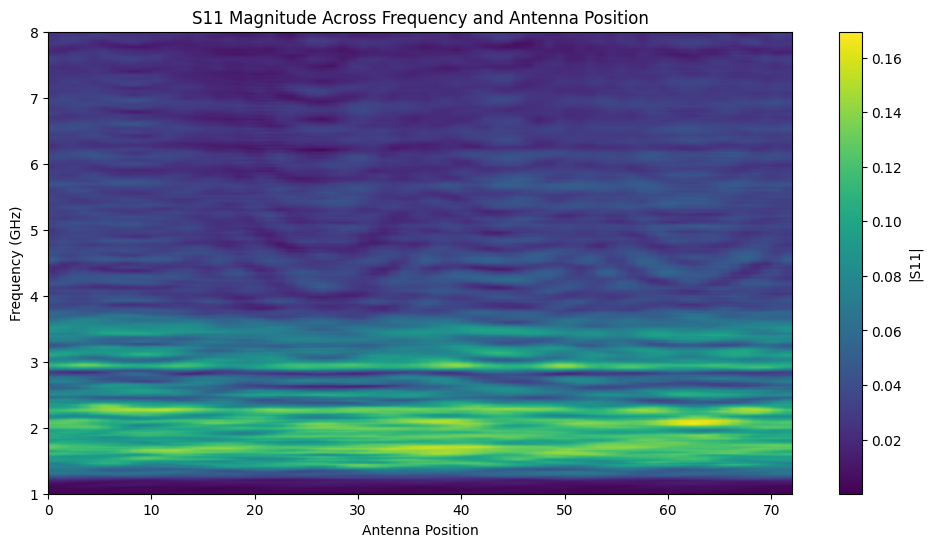

In [18]:
# Visualize the magnitude of S11 for one experiment
# across all frequencies and all 72 antenna positions

experiment_idx = 0

s11_experiment = s11_data[experiment_idx, :, :]

magnitude = np.abs(s11_experiment)

plt.figure(figsize=(12, 6))

plt.imshow(
    magnitude,
    aspect='auto',
    origin='lower',
    extent=[0, 72, 1, 8]
)

plt.xlabel("Antenna Position")
plt.ylabel("Frequency (GHz)")
plt.title("S11 Magnitude Across Frequency and Antenna Position")

plt.colorbar(label="|S11|")

plt.show()

In [19]:
# Create tumor-reference pairs

tumor_indices = []
reference_indices = []

for i in range(0, len(metadata_df), 2):

    tumor_idx = i
    reference_idx = i + 1

    tumor_indices.append(tumor_idx)
    reference_indices.append(reference_idx)

print("Number of pairs:", len(tumor_indices))

print("\nFirst 5 pairs:")
for i in range(5):
    print(
        "Tumor:", metadata_df.iloc[tumor_indices[i]]["id"],
        "Reference:", metadata_df.iloc[reference_indices[i]]["id"]
    )

Number of pairs: 100

First 5 pairs:
Tumor: 1 Reference: 2
Tumor: 4 Reference: 5
Tumor: 7 Reference: 8
Tumor: 10 Reference: 11
Tumor: 13 Reference: 14


In [20]:
# Calculate tumor-reference difference

delta_s11 = []

for tumor_idx, reference_idx in zip(tumor_indices, reference_indices):

    tumor = s11_data[tumor_idx, :, :]
    reference = s11_data[reference_idx, :, :]

    difference = tumor - reference

    delta_s11.append(difference)

delta_s11 = np.array(delta_s11)

print("ΔS11 shape:", delta_s11.shape)
print("ΔS11 data type:", delta_s11.dtype)

ΔS11 shape: (100, 1001, 72)
ΔS11 data type: complex128


In [21]:
# Magnitude of the tumor-induced S11 change

delta_magnitude = np.abs(delta_s11)

print("Shape:", delta_magnitude.shape)
print("Minimum:", delta_magnitude.min())
print("Maximum:", delta_magnitude.max())
print("Mean:", delta_magnitude.mean())

Shape: (100, 1001, 72)
Minimum: 1.25711888836859e-07
Maximum: 0.03830117677642487
Mean: 0.0014758604497310825


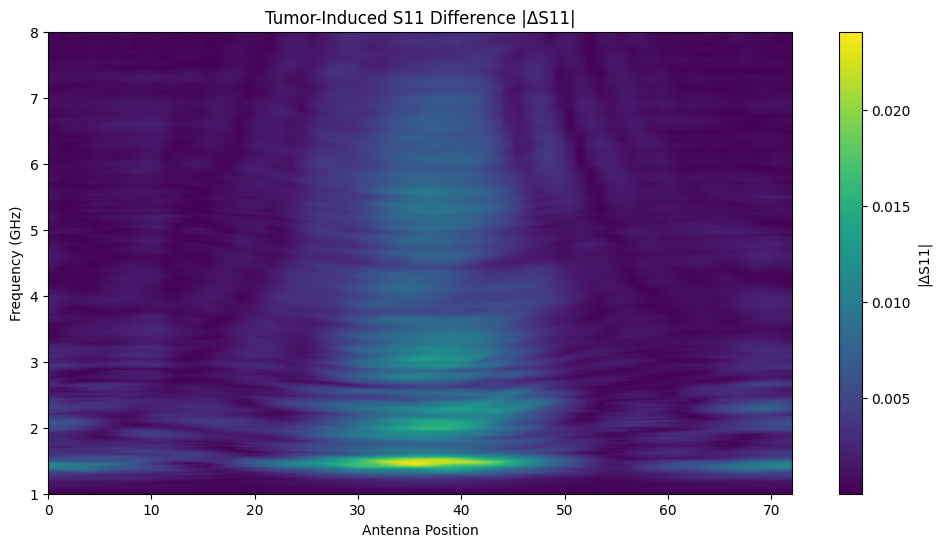

In [22]:
# Visualize tumor-induced S11 change
# for the first tumor case

plt.figure(figsize=(12, 6))

plt.imshow(
    delta_magnitude[0],
    aspect='auto',
    origin='lower',
    extent=[0, 72, 1, 8]
)

plt.xlabel("Antenna Position")
plt.ylabel("Frequency (GHz)")
plt.title("Tumor-Induced S11 Difference |ΔS11|")

plt.colorbar(label="|ΔS11|")

plt.show()

In [23]:
try:
    from umbmid.sigproc import iczt
    print("ICZT imported successfully!")
except Exception as e:
    print("ICZT is not available yet.")
    print("Error:", e)

ICZT is not available yet.
Error: No module named 'umbmid'


In [24]:
# Get the tumor metadata
tumor_metadata = metadata_df.iloc[tumor_indices].copy()

# Create a location label
tumor_metadata["location"] = (
    tumor_metadata["tum_x"].astype(str) + "_" +
    tumor_metadata["tum_y"].astype(str)
)

print(tumor_metadata["location"].value_counts())

location
-2.25_-2.25    70
-2.25_2.25     15
2.25_-2.25     10
2.25_2.25       5
Name: count, dtype: int64


In [25]:
location_map = {
    (-2.25, 2.25): 0,
    (2.25, 2.25): 1,
    (-2.25, -2.25): 2,
    (2.25, -2.25): 3
}

y = np.array([
    location_map[(x, y_coord)]
    for x, y_coord in zip(
        tumor_metadata["tum_x"],
        tumor_metadata["tum_y"]
    )
])

print("Labels:")
print(y)

print("\nNumber of samples:", len(y))
print("Class counts:", np.bincount(y))

Labels:
[1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 3 3 3 3 3 3 3 3 3 3 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]

Number of samples: 100
Class counts: [15  5 70 10]


In [26]:
# Frequency axis
frequency = np.linspace(1, 8, 1001)

# Define frequency bands
bands = [
    (1, 2),
    (2, 3),
    (3, 4),
    (4, 5),
    (5, 6),
    (6, 7),
    (7, 8)
]

features = []

for experiment in delta_magnitude:

    experiment_features = []

    for f_low, f_high in bands:

        mask = (frequency >= f_low) & (frequency < f_high)

        # Average |ΔS11| within this frequency band
        band_average = experiment[mask, :].mean(axis=0)

        experiment_features.extend(band_average)

    features.append(experiment_features)

X = np.array(features)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100, 504)
y shape: (100,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 80
Testing samples: 20


In [28]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [29]:
y_pred = model.predict(X_test)

print("Actual labels:")
print(y_test)

print("\nPredicted labels:")
print(y_pred)

Actual labels:
[2 2 2 2 2 2 2 3 0 0 2 3 1 2 0 2 2 2 2 2]

Predicted labels:
[2 2 2 2 2 2 2 3 0 0 2 3 1 2 0 2 2 2 2 2]


In [30]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Accuracy: 1.0
Test Accuracy (%): 100.0


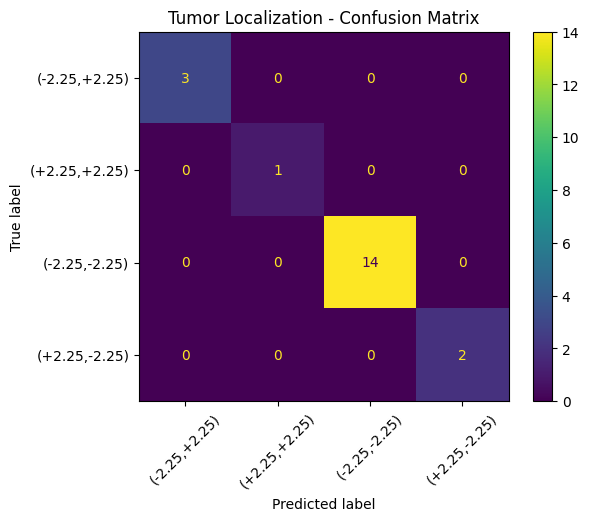

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "(-2.25,+2.25)",
        "(+2.25,+2.25)",
        "(-2.25,-2.25)",
        "(+2.25,-2.25)"
    ]
)

disp.plot()
plt.title("Tumor Localization - Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=skf,
    scoring="accuracy"
)

print("Cross-validation accuracies:")
print(scores)

print("\nMean accuracy:", scores.mean())
print("Standard deviation:", scores.std())

Cross-validation accuracies:
[1.   0.95 0.95 0.9  1.  ]

Mean accuracy: 0.96
Standard deviation: 0.03741657386773941


In [33]:
print("Unique phantoms:")
print(tumor_metadata["phant_id"].nunique())

print("\nPhantom counts:")
print(tumor_metadata["phant_id"].value_counts())

print("\nTumor diameters:")
print(tumor_metadata["tum_diam"].value_counts().sort_index())

print("\nTumor locations:")
print(
    tumor_metadata[
        ["tum_x", "tum_y", "tum_z"]
    ].drop_duplicates()
)

Unique phantoms:
20

Phantom counts:
phant_id
A2F1      5
A2F11     5
A2F12     5
A16F1     5
A16F11    5
A16F14    5
A14F1     5
A14F12    5
A3F1      5
A3F3      5
A3F2      5
A3F11     5
A14F11    5
A2F2      5
A16F2     5
A2F3      5
A16F3     5
A14F3     5
A3F12     5
A14F2     5
Name: count, dtype: int64

Tumor diameters:
tum_diam
1.0    20
1.5    20
2.0    20
2.5    20
3.0    20
Name: count, dtype: int64

Tumor locations:
    tum_x  tum_y  tum_z
0    2.25   2.25   -6.5
10  -2.25   2.25   -6.5
30   2.25  -2.25   -6.5
50  -2.25  -2.25   -6.5


In [34]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Phantom IDs for the 100 tumor samples
groups = tumor_metadata["phant_id"].values

print("Number of samples:", len(groups))
print("Number of unique phantoms:", len(np.unique(groups)))

# Random Forest
rf_group = RandomForestClassifier(
    n_estimators=300,
    random_state=42
)

# 5-fold group cross-validation
gkf = GroupKFold(n_splits=5)

group_scores = cross_val_score(
    rf_group,
    X,
    y,
    groups=groups,
    cv=gkf,
    scoring="accuracy"
)

print("\nGroup cross-validation accuracies:")
print(group_scores)

print("\nMean group accuracy:", group_scores.mean())
print("Standard deviation:", group_scores.std())

Number of samples: 100
Number of unique phantoms: 20

Group cross-validation accuracies:
[1.   1.   1.   0.95 0.7 ]

Mean group accuracy: 0.93
Standard deviation: 0.11661903789690603
